# Xenium PANZONER: Step by Step

## Setup

In [1]:
from pathlib import Path
import json, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, Circle
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
from scipy import sparse
from scipy.sparse.csgraph import connected_components
import alphashape, shapely
import anndata as ad
from shapely.geometry import mapping
from IPython.display import display

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
FONT = Path('/home/biotree/.local/share/fonts/msttcorefonts/Arial.ttf')
if not FONT.exists():
    raise FileNotFoundError('Set FONT to an actual Arial.ttf file before running.')
font_manager.fontManager.addfont(str(FONT))
plt.rcParams.update({'font.family': 'Arial', 'font.size': 9,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'axes.linewidth': 0.6, 'figure.dpi': 120, 'savefig.dpi': 300})
P = {
    'radius_um': 50,
    'core_threshold_strict': 0.8,
    'peri_threshold': 0.66,
    'border_threshold': 0.33,
    'min_region_cells': 50,
    'inner_um': 30,
    'outer_um': 50,
    'alpha_per_um': 0.02,
}
COLORS = {'Other': '#d9d9d9', 'Hypo': '#1c71a4', 'core': '#1c71a4',
    'peri_core': '#ee7a34', 'border': '#812b99', 'isolated': '#c974ad',
    'Candidate': '#ee7a34', 'Retained': '#1c71a4', 'Excluded': '#c974ad',
    'Inner 30 um (Hypo)': '#1c71a4', 'Outer 50 um': '#ee7a34'}

def base(ax, title):
    ax.set(xlim=(XMIN, XMAX), ylim=(YMAX, YMIN), aspect='equal')
    ax.set_title(title, fontsize=12, pad=10)
    ax.axis('off')
    x, y = XMIN + 15, YMAX - 18
    ax.plot([x, x+50], [y,y], color='black', lw=1.3)
    ax.text(x+25, y-6, '50 μm', ha='center', va='bottom', fontsize=8)

def dots(ax, labels, colors, size=8):
    labels = np.asarray(labels)
    for name, color in colors.items():
        selected = labels == name
        if selected.any():
            ax.scatter(xy[selected,0], xy[selected,1], s=size, c=color,
                       edgecolors='none', label=name, rasterized=False)

def key(ax, colors):
    handles=[Line2D([],[],marker='o',ls='',color=c,label=k,markersize=5)
             for k,c in colors.items()]
    ax.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,-.015),
              ncol=min(4,len(handles)),frameon=False,fontsize=8,handletextpad=.3,
              columnspacing=1)

def outline(ax, geometry, color='black', style='-', width=1):
    if geometry.is_empty: return
    if geometry.geom_type == 'Polygon':
        for ring in [geometry.exterior, *geometry.interiors]:
            q=np.asarray(ring.coords); ax.plot(q[:,0],q[:,1],color=color,lw=width,ls=style)
    elif hasattr(geometry,'geoms'):
        for g in geometry.geoms: outline(ax,g,color,style,width)

def save(fig, name):
    fig.savefig(RESULTS / (name+'.png'), bbox_inches='tight', facecolor='white')
    fig.savefig(RESULTS / (name+'.pdf'), bbox_inches='tight', facecolor='white')
    fig.savefig(RESULTS / (name+'.svg'), bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)

def categorical_plot(labels, colors, title, name, geometry=None):
    fig,ax=plt.subplots(figsize=(5.5,5.2))
    dots(ax,labels,colors);base(ax,title)
    if geometry is not None: outline(ax,geometry)
    key(ax,colors);save(fig,name)

parameter_table = pd.DataFrame([['Neighborhood radius', '50 μm'], ['Core', 'p > 0.80'], ['Peri-core', '0.66 ≤ p ≤ 0.80'], ['Border', '0.33 ≤ p < 0.66'], ['Isolated', 'p < 0.33 or no neighbors'], ['Minimum region size', '50 cells'], ['Interior gradient', '30 μm; Hypo only'], ['Exterior gradient', '50 μm'], ['Alpha-shape alpha', '0.02 μm⁻¹']], columns=['Parameter','Value'])
parameter_table.to_csv(RESULTS/'parameters.tsv',sep='\t',index=False)
display(parameter_table)

,Parameter,Value
0,Neighborhood radius,50 μm
1,Core,p > 0.80
2,Peri-core,0.66 ≤ p ≤ 0.80
3,Border,0.33 ≤ p < 0.66
4,Isolated,p < 0.33 or no neighbors
5,Minimum region size,50 cells
6,Interior gradient,30 μm; Hypo only
7,Exterior gradient,50 μm
8,Alpha-shape alpha,0.02 μm⁻¹


## Selected Region

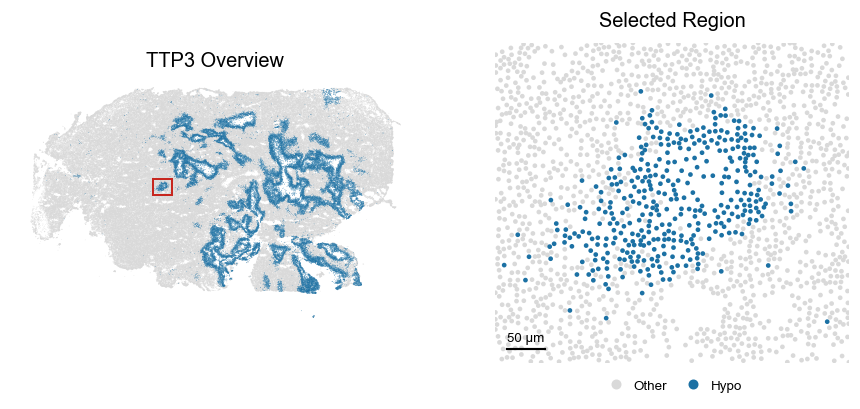

In [2]:
from IPython.display import Image
display(Image(filename='assets/selected_region.png'))

## Step 1 | ROI AnnData

site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 1798 × 0
    obs: 'is_hypo'
    obsm: 'spatial'

,ROI cells,Hypo cells
0,1798,381


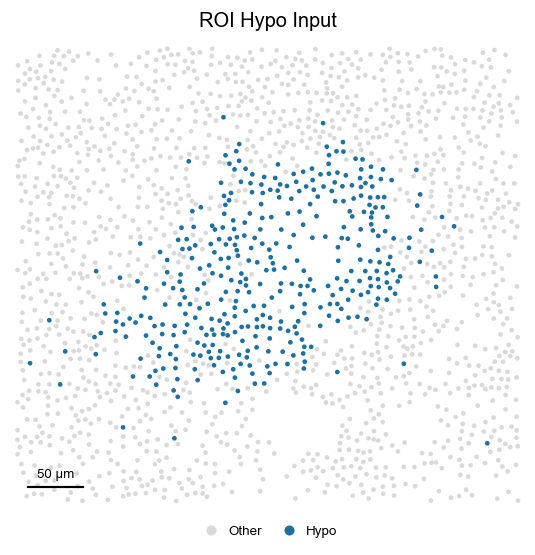

In [3]:
adata = ad.read_h5ad(ROOT / 'data/roi_input.h5ad')
assert adata.obs_names.is_unique
assert list(adata.obs.columns) == ['is_hypo']
assert adata.obs['is_hypo'].isin([False, True]).all()
xy = np.asarray(adata.obsm['spatial'], dtype=float)
assert xy.shape == (adata.n_obs, 2) and np.isfinite(xy).all()
hypo = adata.obs['is_hypo'].to_numpy(bool)
df = pd.DataFrame({'cell_id': adata.obs_names, 'x_um': xy[:,0],
                   'y_um': xy[:,1], 'is_hypo': hypo.astype(int)})
XMIN, YMIN = xy.min(axis=0) - 5
XMAX, YMAX = xy.max(axis=0) + 5
labels = np.where(hypo, 'Hypo', 'Other')
display(adata)
display(pd.DataFrame({'ROI cells':[adata.n_obs], 'Hypo cells':[int(hypo.sum())]}))
categorical_plot(labels, {k:COLORS[k] for k in ['Other','Hypo']},
                 'ROI Hypo Input', '01_roi_input')

## Step 2 | Neighborhood Graph

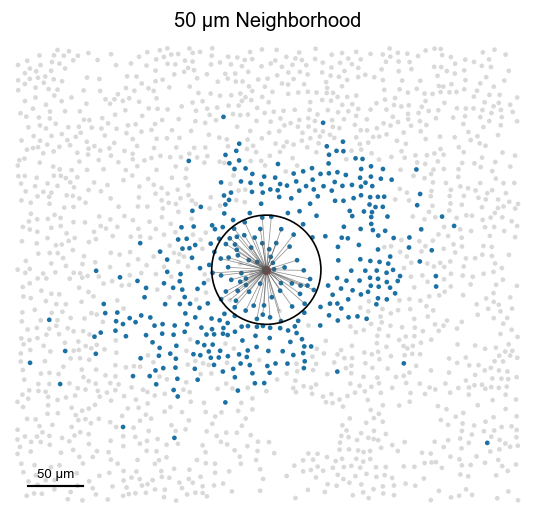

In [4]:
# Undirected Euclidean graph: distance <= 50 um, self excluded.
pairs=cKDTree(xy).query_pairs(P['radius_um'], output_type='ndarray')
a,b=pairs.T
G=sparse.coo_matrix((np.ones(2*len(a),dtype=np.int64),
    (np.r_[a,b],np.r_[b,a])),shape=(len(df),len(df))).tocsr()
assert (G!=G.T).nnz==0 and G.diagonal().sum()==0
sparse.save_npz(RESULTS/'radius_graph.npz',G)
adata.obsp['spatial_connectivities'] = G
# Show one complete neighborhood; all graph edges remain in radius_graph.npz.
anchor=xy[hypo].mean(axis=0)
center=int(np.argmin(np.linalg.norm(xy-anchor,axis=1)))
neighbors=G.indices[G.indptr[center]:G.indptr[center+1]]
fig,ax=plt.subplots(figsize=(5.5,5.2))
dots(ax,labels,{k:COLORS[k] for k in ['Other','Hypo']})
ax.add_collection(LineCollection([[xy[center],xy[j]] for j in neighbors],
                  colors='#555555',linewidths=.45,alpha=.65))
ax.add_patch(Circle(xy[center],P['radius_um'],fill=False,color='black',lw=1))
ax.scatter(*xy[center],s=35,c='#c7271f',edgecolors='white',linewidths=.5)
base(ax,'50 μm Neighborhood');save(fig,'02_neighborhood')

## Step 3 | Hypo Neighbor Fraction

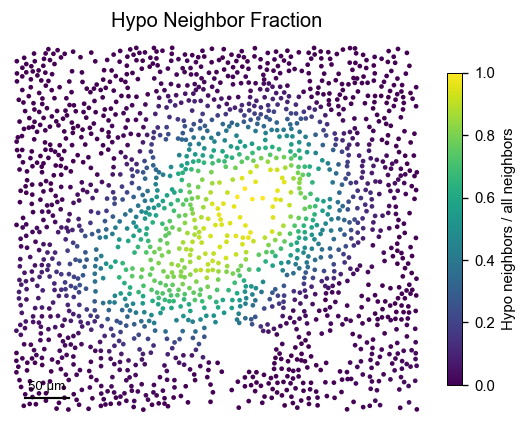

In [5]:
degree=np.asarray(G.sum(axis=1)).ravel()
nh=np.asarray(G@hypo.astype(int)).ravel()
fraction=np.divide(nh,degree,out=np.full(len(df),np.nan),where=degree>0)
fig,ax=plt.subplots(figsize=(5.5,5.2))
m=np.ones(len(df),dtype=bool)
p=ax.scatter(xy[m,0],xy[m,1],c=fraction[m],s=8,cmap='viridis',vmin=0,vmax=1,edgecolors='none')
base(ax,'Hypo Neighbor Fraction')
fig.colorbar(p,ax=ax,shrink=.65,label='Hypo neighbors / all neighbors')
save(fig,'03_neighbor_fraction')

## Step 4 | Cell Status

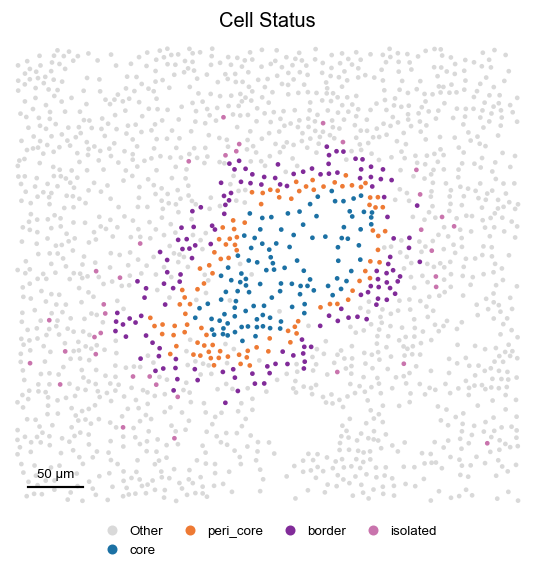

,count
Status,
Other,1417
border,137
core,111
peri_core,97
isolated,36


In [6]:
# Only Hypo-labeled cells enter these PAN status classes.
status=np.full(len(df),'Other',dtype=object)
status[hypo]='isolated'
status[hypo&(fraction>=P['border_threshold'])]='border'
status[hypo&(fraction>=P['peri_threshold'])]='peri_core'
status[hypo&(fraction>P['core_threshold_strict'])]='core'
categorical_plot(status,{k:COLORS[k] for k in ['Other','core','peri_core','border','isolated']},
                 'Cell Status','04_cell_status')
display(pd.Series(status,name='Cells').value_counts().rename_axis('Status').to_frame())

## Step 5 | Connected Hypo Regions

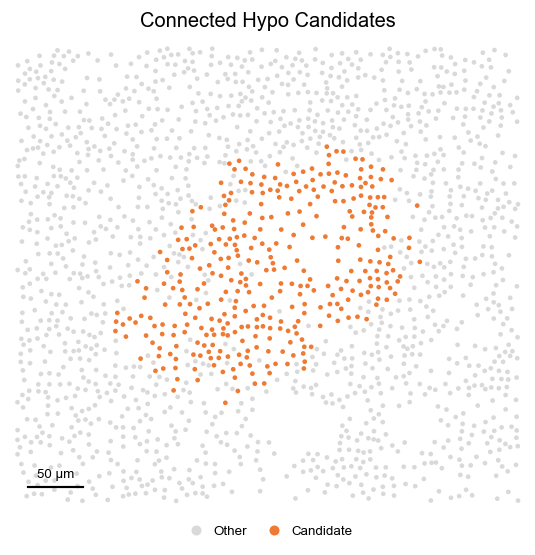

,component,Hypo_cells,retained
0,0,345,True


In [7]:
# Connect core, peri-core and border cells into regions.
qualified=np.isin(status,['core','peri_core','border'])
pos=np.flatnonzero(qualified)
n_components,cc=connected_components(G[pos][:,pos],directed=False)
component=np.full(len(df),-1,dtype=int); component[pos]=cc
sizes=np.bincount(cc)
component_table=pd.DataFrame({'component':np.arange(n_components),'Hypo_cells':sizes})
component_table['retained']=component_table.Hypo_cells>=P['min_region_cells']
component_table.to_csv(RESULTS/'components.tsv',sep='\t',index=False)
categorical_plot(np.where(qualified,'Candidate','Other'),
    {k:COLORS[k] for k in ['Other','Candidate']},'Connected Hypo Candidates','05_candidates')
display(component_table)

## Step 6 | Minimum Region Size

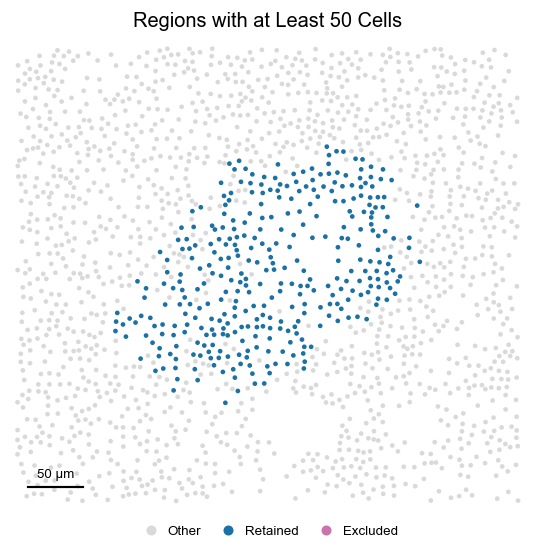

In [8]:
retained_ids=np.flatnonzero(sizes>=P['min_region_cells'])
assert len(retained_ids)>0
retained=np.isin(component,retained_ids)
# Select the largest retained component.
target_id=int(retained_ids[np.argmax(sizes[retained_ids])])
target=component==target_id
filter_labels=np.full(len(df),'Other',dtype=object)
filter_labels[qualified&~retained]='Excluded';filter_labels[retained]='Retained'
categorical_plot(filter_labels,{k:COLORS[k] for k in ['Other','Retained','Excluded']},
    'Regions with at Least 50 Cells','06_retained_regions')


## Step 7 | PAN Boundary

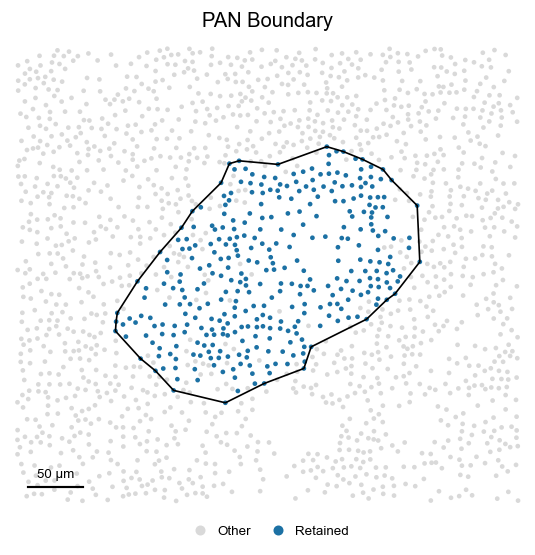

In [9]:
# Construct the alpha-shape boundary.
polygon=alphashape.alphashape(xy[target],P['alpha_per_um'])
assert polygon.geom_type=='Polygon' and polygon.is_valid and not polygon.is_empty
feature={'type':'FeatureCollection','features':[{'type':'Feature',
    'properties':{'region':'ROI','alpha_per_um':P['alpha_per_um'],
                  'n_region_cells':int(target.sum())},'geometry':mapping(polygon)}]}
(RESULTS/'PAN_boundary.geojson').write_text(json.dumps(feature)+'\n')
categorical_plot(np.where(target,'Retained','Other'),
    {k:COLORS[k] for k in ['Other','Retained']},'PAN Boundary','07_pan_boundary',polygon)

## Step 8 | Signed Boundary Distance

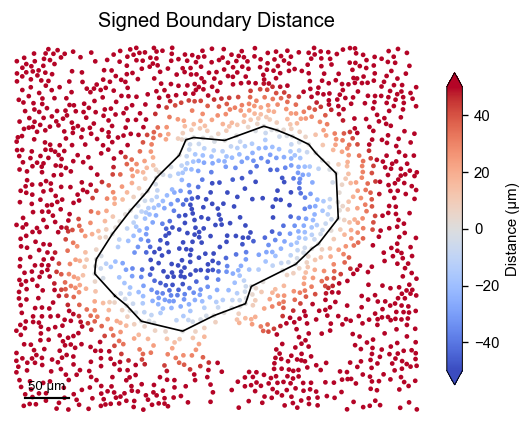

In [10]:
points=shapely.points(xy)
inside=np.asarray(shapely.covers(polygon,points))
distance=np.asarray(shapely.distance(points,polygon.boundary))
signed=np.where(inside,-distance,distance)
fig,ax=plt.subplots(figsize=(5.5,5.2))
m=np.ones(len(df),dtype=bool)
p=ax.scatter(xy[m,0],xy[m,1],c=signed[m],s=8,cmap='coolwarm',vmin=-50,vmax=50,edgecolors='none')
outline(ax,polygon);base(ax,'Signed Boundary Distance')
fig.colorbar(p,ax=ax,shrink=.65,label='Distance (μm)',extend='both')
save(fig,'08_signed_distance')

## Step 9 | Inner 30 μm

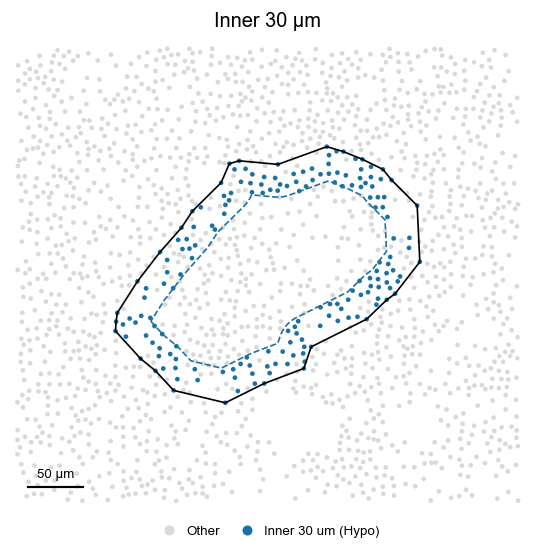

In [11]:
inner=inside & hypo & (distance<=P['inner_um'])
inner_labels=np.where(inner,'Inner 30 um (Hypo)','Other')
fig,ax=plt.subplots(figsize=(5.5,5.2))
colors={k:COLORS[k] for k in ['Other','Inner 30 um (Hypo)']}
dots(ax,inner_labels,colors);outline(ax,polygon)
outline(ax,polygon.buffer(-P['inner_um']),COLORS['Hypo'],'--')
base(ax,'Inner 30 μm');key(ax,colors);save(fig,'09_inner_30um')

## Step 10 | Outer 50 μm

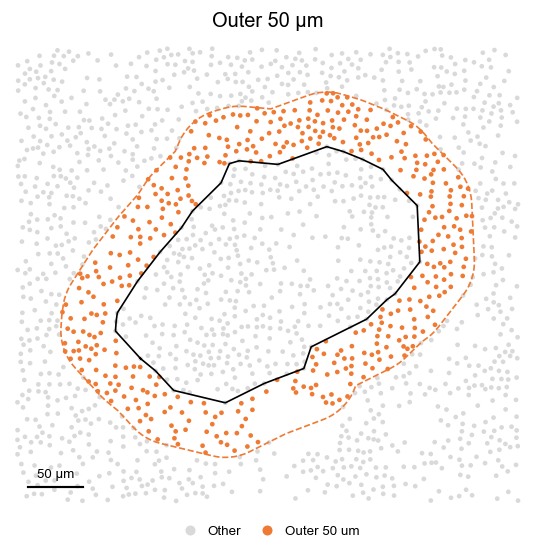

In [12]:
outer=(~inside) & (distance<=P['outer_um'])
outer_labels=np.where(outer,'Outer 50 um','Other')
fig,ax=plt.subplots(figsize=(5.5,5.2))
colors={k:COLORS[k] for k in ['Other','Outer 50 um']}
dots(ax,outer_labels,colors);outline(ax,polygon)
outline(ax,polygon.buffer(P['outer_um']),COLORS['Outer 50 um'],'--')
base(ax,'Outer 50 μm');key(ax,colors);save(fig,'10_outer_50um')

## Step 11 | Final Zonation

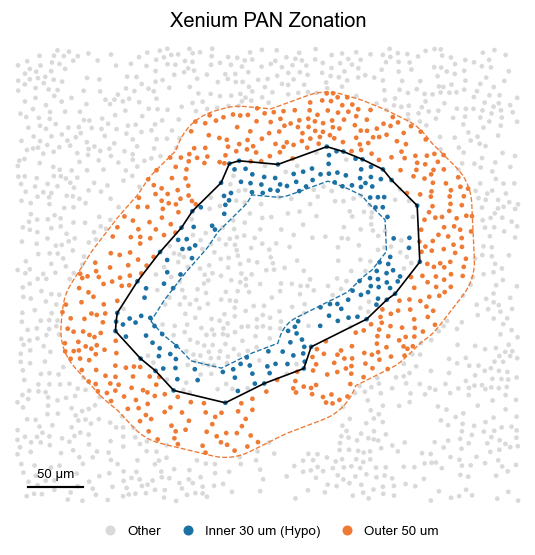

,Group,Cells
0,Retained PAN cells,345
1,Inner 30 um (Hypo),174
2,Outer 50 um,435


In [13]:
zone=np.full(len(df),'Other',dtype=object)
zone[inner]='Inner 30 um (Hypo)';zone[outer]='Outer 50 um'
colors={k:COLORS[k] for k in ['Other','Inner 30 um (Hypo)','Outer 50 um']}
fig,ax=plt.subplots(figsize=(5.5,5.2))
dots(ax,zone,colors);outline(ax,polygon)
outline(ax,polygon.buffer(-P['inner_um']),COLORS['Hypo'],'--',.8)
outline(ax,polygon.buffer(P['outer_um']),COLORS['Outer 50 um'],'--',.8)
base(ax,'Xenium PAN Zonation');key(ax,colors);save(fig,'11_final_zonation')

result=df.assign(n_neighbors=degree,n_hypo_neighbors=nh,
    hypo_neighbor_fraction=fraction,cell_status=status,component_id=component,
    retained_region=retained,target_region=target,inside_pan=inside,
    signed_distance_um=signed,zone=zone)
result.to_csv(RESULTS/'cell_annotations.tsv',sep='\t',index=False)
result.loc[inner|outer].to_csv(RESULTS/'gradient_cells.tsv',sep='\t',index=False)
summary=pd.DataFrame({'Group':['Retained PAN cells','Inner 30 um (Hypo)','Outer 50 um'],
                      'Cells':[int(target.sum()),int(inner.sum()),int(outer.sum())]})
summary.to_csv(RESULTS/'zone_counts.tsv',sep='\t',index=False)
display(summary)

annotations = result.set_index('cell_id').drop(columns=['x_um','y_um','is_hypo'])
adata.obs = adata.obs.join(annotations)
adata.uns['panzoner_parameters'] = P
adata.uns['pan_boundary_geojson'] = json.dumps(feature)
adata.write_h5ad(RESULTS/'roi_annotated.h5ad', compression='gzip')
versions = {p:importlib.metadata.version(p) for p in
            ['anndata','numpy','pandas','scipy','matplotlib','shapely','alphashape']}
_ = (RESULTS/'environment.json').write_text(json.dumps(versions,indent=2)+'\n')


## Step 12 | Stepwise Overview

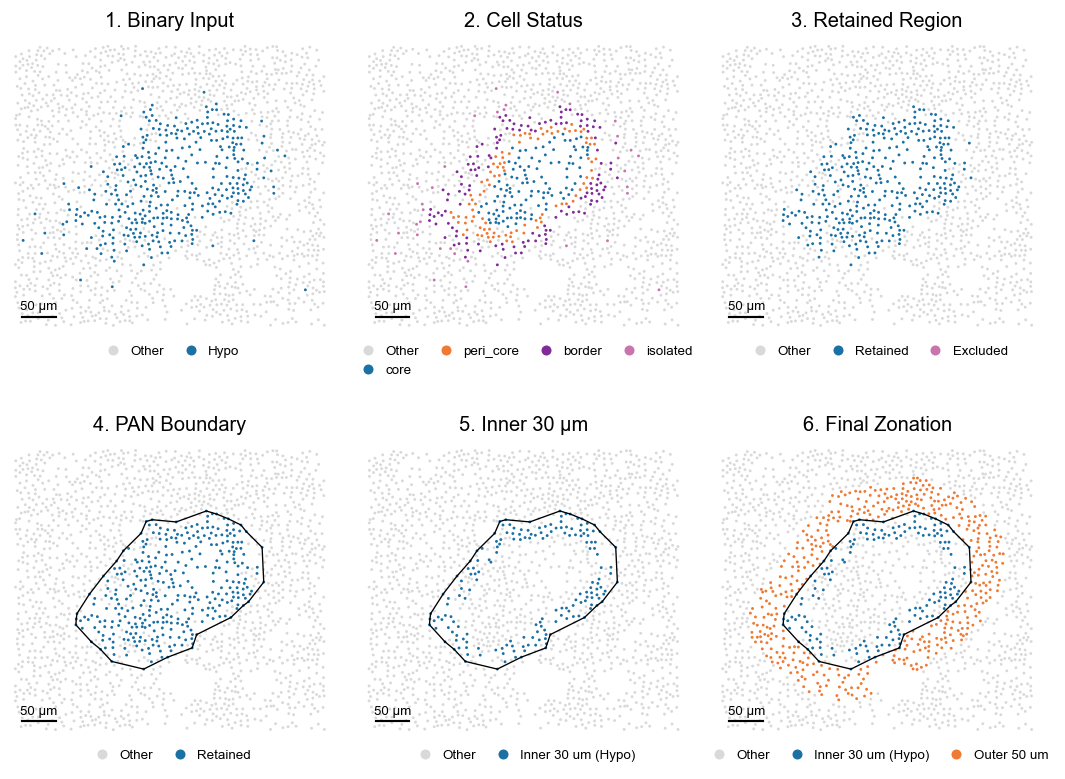

In [14]:
fig,axes=plt.subplots(2,3,figsize=(11,7.5))
panels=[(labels,{k:COLORS[k] for k in ['Other','Hypo']},'1. Binary Input',False),
 (status,{k:COLORS[k] for k in ['Other','core','peri_core','border','isolated']},'2. Cell Status',False),
 (filter_labels,{k:COLORS[k] for k in ['Other','Retained','Excluded']},'3. Retained Region',False),
 (np.where(target,'Retained','Other'),{k:COLORS[k] for k in ['Other','Retained']},'4. PAN Boundary',True),
 (inner_labels,{k:COLORS[k] for k in ['Other','Inner 30 um (Hypo)']},'5. Inner 30 μm',True),
 (zone,colors,'6. Final Zonation',True)]
for ax,(values,palette,title,show_boundary) in zip(axes.ravel(),panels):
    dots(ax,values,palette,size=3);base(ax,title)
    if show_boundary: outline(ax,polygon,width=.8)
    key(ax,palette)
fig.subplots_adjust(wspace=.12,hspace=.4)
save(fig,'12_stepwise_overview')